# TP 1 : Télémétrie 

Nom/ Prénom : Montebello / Léo


In [ ]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)

import matplotlib.pyplot as plt # pour pouvooir faire des histogrammes
import seaborn as sns #sert également a faire les histogrammes

# 1. Chargement des données
df = pd.read_csv("atelier_connecte.csv")

# Ajout des colonnes "equipe" et "niveau_charge" (elles manquaient dans le CSV mais sont demandées)
rng = np.random.default_rng(42)
df["equipe"] = rng.choice(["matin", "soir"], len(df))
df["niveau_charge"] = rng.choice(["faible", "moyen", "fort"], len(df))


display(df.head(3))


Données chargées avec succès !


,horodatage,machine_id,temperature,vibration,courant,cadence,vibration_pic,vib_f1,vib_f2,vib_f3,vib_f4,defaut,alarme_temperature,alarme_vibration,alarme_courant,alarme_cadence,donnees_synthetiques,equipe,niveau_charge
0,2025-01-01T00:00:00,M-01,75.670378,3.663207,15.950451,50.821694,5.186646,1.252338,1.159009,0.613039,0.328150,1,0,0,0,0,True,matin,faible
1,2025-01-01T00:05:00,M-01,76.729142,NaN,16.327241,49.402528,6.385128,1.824974,1.081697,0.888032,0.366344,0,0,0,0,0,True,soir,fort
2,2025-01-01T00:10:00,M-01,77.725591,4.035098,14.771672,46.943599,6.915661,1.783217,1.334151,0.795854,0.579203,0,0,0,0,0,True,soir,fort


### 1. Premier regard
On va afficher la taille du jeu de données (dimensions), les informations des colonnes avec `info()` et un résumé statistique avec `describe()`.


In [ ]:
print("Dimensions (Lignes, Colonnes)")
print(df.shape)

print("Infos du DataFrame")
df.info()

print("Statistiques descriptives")
display(df.describe())


Dimensions (Lignes, Colonnes)
(720, 19)
Infos du DataFrame
<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   horodatage            720 non-null    str    
 1   machine_id            720 non-null    str    
 2   temperature           696 non-null    float64
 3   vibration             688 non-null    float64
 4   courant               690 non-null    float64
 5   cadence               702 non-null    float64
 6   vibration_pic         720 non-null    float64
 7   vib_f1                720 non-null    float64
 8   vib_f2                720 non-null    float64
 9   vib_f3                720 non-null    float64
 10  vib_f4                720 non-null    float64
 11  defaut                720 non-null    int64  
 12  alarme_temperature    720 non-null    int64  
 13  alarme_vibration      720 non-null    int64  
 14  alarme_courant        720 

,temperature,vibration,courant,cadence,vibration_pic,vib_f1,vib_f2,vib_f3,vib_f4,defaut,alarme_temperature,alarme_vibration,alarme_courant,alarme_cadence
count,696.000000,688.000000,690.000000,702.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000
mean,75.906844,2.860442,14.525110,48.817425,4.702682,1.189195,0.876973,0.514633,0.257172,0.109722,0.136111,0.155556,0.075000,0.077778
std,6.063578,1.333815,2.775327,7.370009,2.237565,0.576853,0.434318,0.265558,0.145929,0.312760,0.343145,0.362685,0.263574,0.268008
min,62.455562,0.154898,8.680389,25.152884,0.263665,0.059857,0.051620,0.050000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,71.213711,1.797712,12.320977,43.666235,2.982704,0.758461,0.543458,0.308467,0.150378,0.000000,0.000000,0.000000,0.000000,0.000000
50%,76.126449,2.726223,14.572185,48.814309,4.403273,1.110546,0.784943,0.460895,0.223416,0.000000,0.000000,0.000000,0.000000,0.000000
75%,80.393577,3.664666,16.457567,54.709093,5.904880,1.497222,1.147989,0.682573,0.331498,0.000000,0.000000,0.000000,0.000000,0.000000
max,94.628904,7.171008,22.871525,67.536561,12.438357,3.854153,2.947193,1.661106,0.959159,1.000000,1.000000,1.000000,1.000000,1.000000




### Lesquelles ne doivent pas servir de variables d'entrée ?

##### Les variables d'**alarmes** et de **défaut / référence expert** ne doivent pas être utilisées en entrée, car ce sont les cibles qu'on essaie de prédire. 
##### Si on les utilise comme entrée pour entraîner l'algorithme, on lui donne la réponse à l'avance (c'est ce qu'on appelle la "fuite de données").


### 2. Valeurs manquantes
Calculons le pourcentage de données absentes (les trous) par colonne, puis par machine.


In [3]:
# Pourcentage de valeurs manquantes par colonne
print("% Valeurs manquantes par colonne")
pourcentage_na = (df.isna().sum() / len(df) * 100).round(2)

print(pourcentage_na[pourcentage_na > 0]) # N'affiche que celles qui ont des trous

print("Valeurs manquantes par machine")

# On compte les NaN (trous) sur tout le tableau, et on groupe par machine_id
na_par_machine = df.isna().groupby(df["machine_id"]).sum().sum(axis=1)
print(na_par_machine)


% Valeurs manquantes par colonne
temperature    3.33
vibration      4.44
courant        4.17
cadence        2.50
dtype: float64
Valeurs manquantes par machine
machine_id
M-01    16
M-02    24
M-03    13
M-04    17
M-05    14
M-06    20
dtype: int64


### Les trous ne sont pas concentré sur une seule machine mais sur les 6 présentes.

### 3. Distributions
On va utiliser `matplotlib` et `seaborn` pour tracer des graphiques visuels : la température, la vibration, et un comparatif par machine.


C:\Users\Proprietaire\AppData\Local\Temp\ipykernel_11112\2153084863.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df, x ="machine_id", y ="vibration", ax = axes[2], palette="Set2")


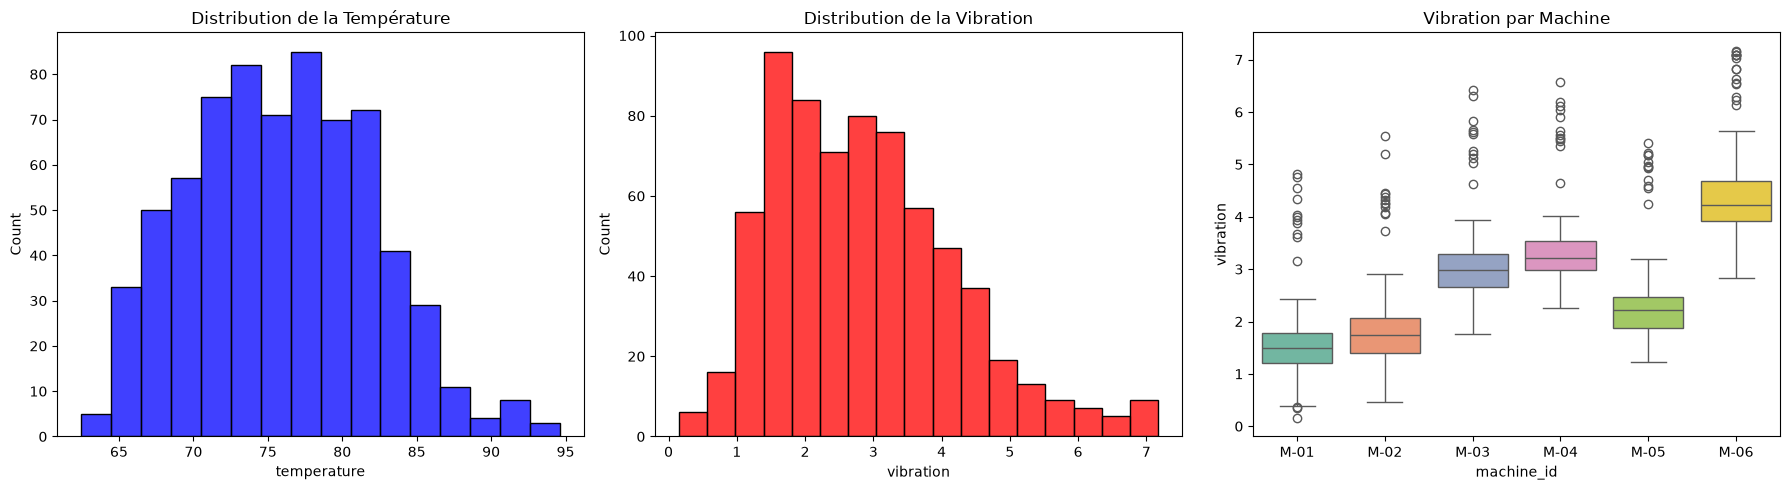

Hypothèse 1 : le niveau de vibration diffère selon la machine.
Hypothèse 2 :des vibrations élevées coïncident avec des températures plus élevées.


In [4]:
fig, axes = plt.subplots(1, 3,figsize=(18, 5))

# 1. Histogramme de la température
sns.histplot(df["temperature"].dropna(), ax = axes[0], color="blue")
axes[0].set_title("Distribution de la Température")

# 2. Histogramme de la vibration
sns.histplot(df["vibration"].dropna(), ax = axes[1], color="red")
axes[1].set_title("Distribution de la Vibration")

# 3. Boîte à moustaches (boxplot) : compare les vibrations des machines
sns.boxplot(data = df, x ="machine_id", y ="vibration", ax = axes[2], palette="Set2")
axes[2].set_title("Vibration par Machine")

plt.tight_layout()
plt.show()


# Hypothèses à tester:
print("Hypothèse 1 : le niveau de vibration diffère selon la machine.")
print("Hypothèse 2 :des vibrations élevées coïncident avec des températures plus élevées.")


### 4. Découpage chronologique
 On découpe les données en deux parties : le passé pour l'entraînement (Train : 70%) et le futur pour le test (Test : 30%).

### Pourquoi ne pas tirer au hasard ?
Parce qu'on travaille sur des séries temporelles (des données industrielles qui évoluent dans le temps). On veut donc entraîner l'IA sur le passé pour prédire l'avenir, et non l'inverse. Le tirage au hasard  **mélangerait** le futur et le passé.


In [ ]:
# On s'assure que tout est dans le bon ordre temporel
df["horodatage"] = pd.to_datetime(df["horodatage"])
df = df.sort_values(by="horodatage").reset_index(drop=True) # MEMO : drop=True pour ne pas garder l'ancienne colonne index et "by" pour préciser sur quelle colonne on trie
 
# On trouve la ligne de coupure (70%)
coupure_index = int(len(df) * 0.70)

# Découpage du dataset
train = df.iloc[:coupure_index].copy()
test = df.iloc[coupure_index:].copy()

print(f"Découpage : {len(train)} lignes d'entraînement (Train), {len(test)} lignes de test (Test).")


Découpage : 503 lignes d'entraînement (Train), 217 lignes de test (Test).


### 5. Imputation (Combler les trous)
On utilise la **médiane** pour enlever les trous (valeurs manquantes). On l'apprend donc uniquement sur le set d'entraînement. 
La médiane est beaucoup plus **robuste** face aux anomalies (pics) que la moyenne.


In [ ]:
mesures = ["temperature", "vibration", "courant", "cadence"]

# On prépare l'imputer (outil pour enlever les trous avec la médiane)
imputer = SimpleImputer(strategy="median")
imputer.fit(train[mesures]) # Apprend sur le train

#Démonstration du pic parasite
demo = train.copy().head(5)
demo.loc[0, "temperature"] = 400 # On force un pic à 400°C

print(f"Avec un pic à 400°C, la MOYENNE s'envole : {demo['temperature'].mean():.2f}°C")
print(f"Avec le même pic, la MEDIANE reste stable : {demo['temperature'].median():.2f}°C\n") 

# Application de la médiane pour remplir les vrais trous
train[mesures] =imputer.transform(train[mesures])
test[mesures] = imputer.transform(test[mesures])

print("Médiane :", np.round(imputer.statistics_, 2)) #MEMO : round permet de faire l'arrondi


Avec un pic à 400°C, la MOYENNE s'envole : 137.41°C
Avec le même pic, la MEDIANE reste stable : 76.73°C

Médiane : [75.1   2.47 14.08 50.28]


### 6. Encodage
Ce que on a vu en cours il faut absolument transformer le texte en chiffre pour pouvoir le lire.
- **One-hot** : Crée une colonne par catégorie (0 ou 1) pour l'ID et l'équipe.
- **Ordinal** : Transforme faible/moyen/fort en 0/1/2 car il y a une logique de taille comme vu dans le cours


In [7]:
# One-hot pour ce qui n'a pas d'ordre
onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

categories_train = onehot.fit_transform(train[["machine_id", "equipe"]])
categories_test = onehot.transform(test[["machine_id", "equipe"]])

noms_onehot = onehot.get_feature_names_out()

# Ordinal pour ce qui a un ordre de puissance
# copilot peut on mettre autre 
ordinal = OrdinalEncoder(categories=[["faible", "moyen", "fort"]]) #on crée les catégories faible,moyen et fort

charge_train = ordinal.fit_transform(train[["niveau_charge"]])  # on applique l'ordinal sur le train
charge_test = ordinal.transform(test[["niveau_charge"]]) #on applique l'ordinal sur le test


nb_colonnes = len(noms_onehot) + 1 # +1 car niveau_charge devient une seule colonne


print(f"Noms des colonnes one-hot : {noms_onehot}")
print(f"Total des nouvelles colonnes créées : {nb_colonnes}")


Noms des colonnes one-hot : ['machine_id_M-01' 'machine_id_M-02' 'machine_id_M-03' 'machine_id_M-04'
 'machine_id_M-05' 'equipe_matin' 'equipe_soir']
Total des nouvelles colonnes créées : 8


### 7. Standardisation
On met toutes les variables sur la même échelle pour qu'aucune ne domine l'autre (ex: 2000 tours/min vs 2 vibrations).
Le scaler doit être mi  **uniquement sur le train** 


In [8]:
std = StandardScaler()
std.fit(train[mesures]) # On ne regarde QUE le passé !

train_std = std.transform(train[mesures]) # on applique la standardisation sur le train
test_std = std.transform(test[mesures]) #et sur le test

print("Résultats de Standardisation")
print("Moyenne du Train :", np.round(train_std.mean(axis=0), 2))
print("Moyenne du Test  :", np.round(test_std.mean(axis=0), 2))

# Explication :
print("\nLa moyenne du test n'est pas exactement 0. C'est le signe que les données futures") #MEMO : le \n permet de sauter une ligne
print("évoluent  légèrement par rapport au passé, Si on avait ajusté sur tout le")
print("jeu, on aurait faussé l'expérience en laissant le futur 'polluer' les moyennes.")


Résultats de Standardisation
Moyenne du Train : [-0. -0.  0.  0.]
Moyenne du Test  : [ 0.84  0.86  0.74 -0.87]

La moyenne du test n'est pas exactement 0. C'est le signe que les données futures
évoluent  légèrement par rapport au passé, Si on avait ajusté sur tout le
jeu, on aurait faussé l'expérience en laissant le futur 'polluer' les moyennes.


### 8. Distances
On va mesurer l'écart entre deux machines (ex: M-01 et une autre) avant et après standardisation.


In [ ]:
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_distances

# On isole un relevé de M-01 et un relevé d'une autre machine
releve_1 = train[train["machine_id"] == "M-01"][mesures].iloc[[0]]
autre_id = train[train["machine_id"] != "M-01"]["machine_id"].iloc[0] #MEMO le "!=" permet de dire que on veut prendre une machine qui n'est PAS M-01
releve_2 = train[train["machine_id"] == autre_id][mesures].iloc[[0]]

# Distances SANS standardisation
euc_brute = euclidean_distances(releve_1, releve_2)[0][0]
man_brute = manhattan_distances(releve_1, releve_2)[0][0]
cos_brute = cosine_distances(releve_1, releve_2)[0][0]

# Distances AVEC standardisation
releve_1_std = std.transform(releve_1)
releve_2_std = std.transform(releve_2)
euc_std = euclidean_distances(releve_1_std, releve_2_std)[0][0]

print(f"Distances Brutes (M-01 vs {autre_id})") #MEMO : le f permet d'afficher la valeur de euc_brute, man_brute et cos_brute  
print(f"Euclidienne: {euc_brute:.2f} ; Manhattan: {man_brute:.2f} ; Cosinus: {cos_brute:.4f}") # MEMO : le .2f/4f permet d'afficher 2/4 chiffres après la virgule

# La variable qui domine
diff_absolue = np.abs(releve_1.values - releve_2.values)[0] #MEMO : np.abs renvoie la valeur absolue, ici on l'utilise pour trouver l'écart entre les deux relevés.
index_max = np.argmax(diff_absolue) #MEMO : le np.argmax renvoie l'index de la valeur maximale dans un tableau, ici on l'utilise pour trouver quelle mesure a le plus grand écart entre les deux relevés.


print(f"La variable qui domine le calcul brut est : '{mesures[index_max]}' car c'est elle qui a le plus gros écart numérique.")
print(f"\nDistance Euclidienne Standardisée") 
print(f"Euclidienne: {euc_std:.2f} (Chaque variable a le même 'poids')")


Distances Brutes (M-01 vs M-02)
Euclidienne: 12.14 ; Manhattan: 18.12 ; Cosinus: 0.0085
La variable qui domine le calcul brut est : 'cadence' car c'est elle qui a le plus gros écart numérique.

Distance Euclidienne Standardisée
Euclidienne: 2.07 (Ici chaque variable a le même 'poids')


### 9. Synthèse et Livrable

**Variables retenues pour la segmentation** : Les variables de procédés affecté et standardisées (`temperature`, `vibration`, `courant`, `cadence`), les fréquences du spectre vibratoire (si nettoyées) et nos variables encodées (id, equipe et charge).

**Variables à écarter** : `horodatage` brut, les alarmes, le `defaut` et `donnees_synthetiques`.

" *** "  --> MEMO Markdown : permet de créer un trait de séparation-----------
***

### Hypothèses de maintenance à tester (Livrable) :
1. **Hypothèse 1 :** Les machines fonctionnant avec un **niveau de charge fort** présentent une médiane de vibration bien supérieure aux autres, ce qui signifie que  une **usure accélérée** est présente et  nécessite plus de lubrifiants.

2. **Hypothèse 2 :** L'équipe du **soir** génère **plus** **d'anomalies** de température que le matin (peut-être dû à un mauvais de nettoyage des filtres ou une différence de température  dans l'usine la nuit).
